# Pre-entrega: análisis de correlación y comportamiento del consumidor

**Estudiante:** Dennys Parra  
**Curso:** Data Science II — Machine Learning, Coderhouse  
**Actividad:** análisis de correlación del módulo 15

## 1. Objetivo y pregunta de negocio

Comparar los coeficientes de Pearson, Spearman y Kendall para estudiar la asociación entre el descuento (`Discount`) y el beneficio (`Profit`) en transacciones simuladas. La pregunta es: **¿cómo se relacionan los descuentos con el beneficio de una línea de pedido?**

Se reutiliza el CSV limpio de Sample Superstore de la entrega del módulo 14. Cada fila es una **línea de pedido**; varias filas pueden corresponder al mismo pedido. `Discount` es una proporción (0,2 equivale a 20 %) y `Profit` es el beneficio registrado por línea. Este análisis describe asociaciones observadas, no identifica consumidores individuales ni demuestra causalidad.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 4)

## 2. Carga y revisión de los datos

Se revisan dimensiones, tipos y faltantes. Para comparar los métodos de manera justa, se conservan las mismas filas con ambos valores presentes; se informa cuántas se excluyen. No se eliminan valores atípicos automáticamente.

In [2]:
ruta_datos = Path("data/dashboard_ventas.csv")
datos = pd.read_csv(ruta_datos)
variables = ["Discount", "Profit", "Sales", "Quantity"]
pares = datos[["Discount", "Profit"]].dropna()

print(f"Filas y columnas: {datos.shape}")
print(f"Pares analizados: {len(pares)}")
print(f"Filas excluidas por valores faltantes en el par: {len(datos) - len(pares)}")
display(pd.DataFrame({"tipo": datos[variables].dtypes.astype(str), "faltantes": datos[variables].isna().sum()}))
display(datos[variables].head())

Filas y columnas: (9994, 21)
Pares analizados: 9994
Filas excluidas por valores faltantes en el par: 0


,tipo,faltantes
Discount,float64,0
Profit,float64,0
Sales,float64,0
Quantity,float64,0


,Discount,Profit,Sales,Quantity
0,0.00,41.9136,261.9600,2.0
1,0.00,219.5820,731.9400,3.0
2,0.00,6.8714,14.6200,2.0
3,0.45,-383.0310,957.5775,5.0
4,0.20,2.5164,22.3680,2.0


## 3. Distribuciones y relación entre variables

Los histogramas muestran la forma de cada distribución y el gráfico de dispersión permite inspeccionar conjuntamente la relación, los empates y los valores extremos. La normalidad no es un requisito para **calcular** una correlación: la forma de la relación y la sensibilidad a valores extremos también importan. Los datos se mantienen en su escala original.

,count,mean,std,min,25%,50%,75%,max
Discount,9994.0,0.1562,0.2065,0.000,0.0000,0.2000,0.200,0.800
Profit,9994.0,28.6569,234.2601,-6599.978,1.7288,8.6665,29.364,8399.976


Asimetría:


,asimetría
Discount,1.6843
Profit,7.5614


Líneas con descuento cero: 4798


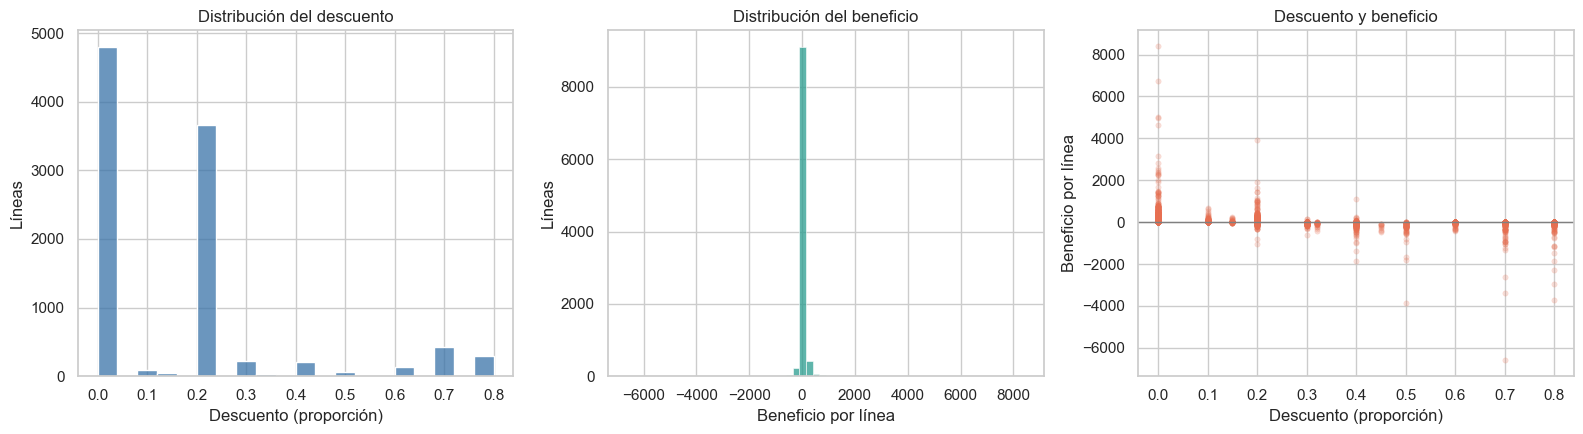

In [3]:
display(pares.describe().T)
print("Asimetría:")
display(pares.skew().to_frame("asimetría"))
print(f"Líneas con descuento cero: {(pares['Discount'] == 0).sum()}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(data=pares, x="Discount", bins=20, ax=axes[0], color="#3973a8")
axes[0].set(title="Distribución del descuento", xlabel="Descuento (proporción)", ylabel="Líneas")
sns.histplot(data=pares, x="Profit", bins=60, ax=axes[1], color="#2a9d8f")
axes[1].set(title="Distribución del beneficio", xlabel="Beneficio por línea", ylabel="Líneas")
sns.scatterplot(data=pares, x="Discount", y="Profit", alpha=0.22, s=15, ax=axes[2], color="#e76f51", edgecolor=None)
axes[2].axhline(0, color="gray", linewidth=1)
axes[2].set(title="Descuento y beneficio", xlabel="Descuento (proporción)", ylabel="Beneficio por línea")
fig.tight_layout()
plt.show()

**Lectura visual:** los descuentos toman valores repetidos, incluido un grupo grande con descuento cero; el beneficio presenta valores extremos positivos y negativos. La escala completa permite ver esos extremos, aunque comprime la zona donde se concentra la mayoría de las líneas. Una marca extrema no es una prueba de error ni una razón suficiente para eliminar una fila.

## 4. Pearson, Spearman y Kendall

- **Pearson** resume la asociación lineal de los valores originales y es sensible a observaciones extremas.
- **Spearman** mide la asociación monotónica entre rangos; una relación monotónica puede no ser lineal.
- **Kendall (tau-b)** compara pares concordantes y discordantes y contempla empates, frecuentes en los descuentos.

Los coeficientes se calculan sobre el mismo conjunto de pares completos. Sus magnitudes no son directamente intercambiables: cada uno resume la asociación de una manera distinta.

In [4]:
metodos = ["pearson", "spearman", "kendall"]
resultados = {metodo: pares["Discount"].corr(pares["Profit"], method=metodo) for metodo in metodos}
for metodo, valor in resultados.items():
    print(f"{metodo.capitalize()}: {valor:.6f}")
display(pd.DataFrame({"coeficiente": resultados}).rename_axis("método"))

Pearson: -0.219487
Spearman: -0.543350
Kendall: -0.428205


,coeficiente
método,
pearson,-0.2195
spearman,-0.5434
kendall,-0.4282


### Matrices de correlación

Se muestran las mismas variables numéricas para los tres métodos. Cada celda usa los pares disponibles de sus dos variables; la conclusión principal se refiere específicamente a `Discount` y `Profit`.

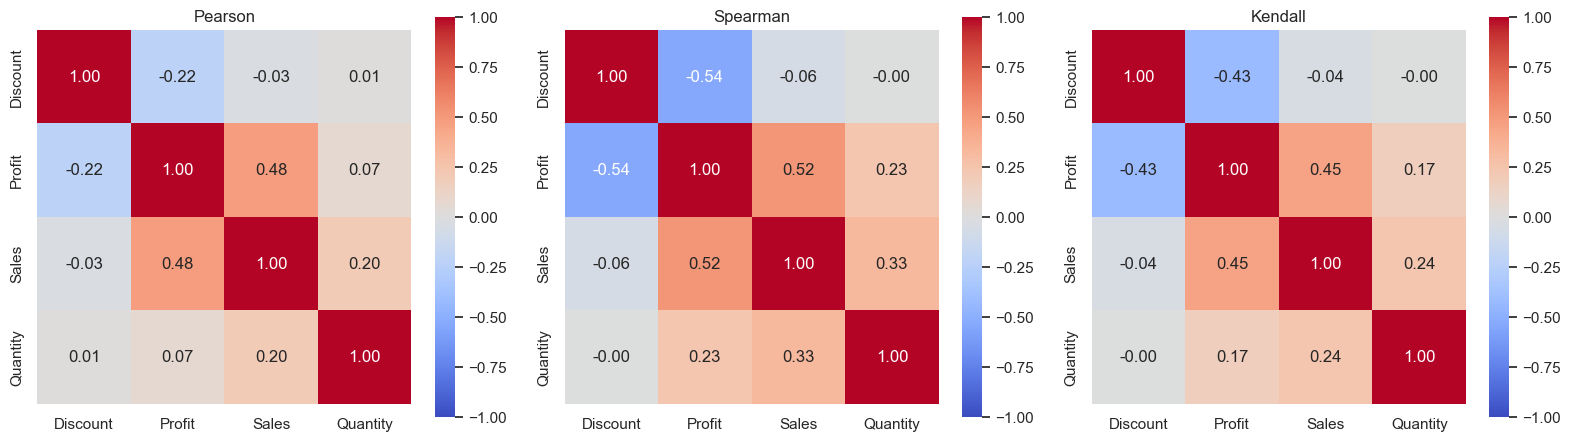

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, metodo in zip(axes, metodos):
    matriz = datos[variables].corr(method=metodo)
    sns.heatmap(matriz, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True, ax=ax)
    ax.set_title(metodo.capitalize())
fig.tight_layout()
plt.show()

## 5. Interpretación y conclusiones

En las 9.994 líneas con datos completos, Pearson es aproximadamente **−0,2195**, Spearman **−0,5434** y Kendall tau-b **−0,4282**. Los tres tienen signo negativo: en este conjunto, los descuentos mayores tienden a asociarse con beneficios menores. Pearson describe una asociación lineal negativa débil; las medidas de rangos muestran una tendencia monotónica negativa más evidente, aunque sus escalas no son directamente comparables.

**Método elegido:** Spearman es la referencia principal para esta pregunta exploratoria porque resume la tendencia por rangos y reduce la influencia de valores extremos sobre la magnitud del coeficiente. Kendall tau-b es un complemento útil por la abundancia de empates en los descuentos. Ninguno es universalmente «el más robusto»: la elección depende del objetivo, los empates y la forma de la relación. Pearson se conserva para describir el componente lineal en la escala original.

**Límite de negocio:** una correlación negativa **no demuestra causalidad**: no permite concluir que aumentar el descuento por sí solo reduzca el beneficio. Pueden intervenir el producto, sus costos, la categoría u otras condiciones no evaluadas. Tampoco hay que interpretar el coeficiente como un porcentaje de reducción del beneficio. Las líneas de un mismo pedido pueden estar relacionadas entre sí; este análisis descriptivo no las trata como evidencia de observaciones independientes.

**Siguiente paso:** comparar la relación por categoría y revisar las observaciones extremas antes de considerar decisiones comerciales. Esto requeriría un análisis adicional; no se ha realizado aquí.